In [1]:
# !pip install -q transformers datasets torch torchaudio sentencepiece pandas

In [2]:
import torch
 
class CFG:
    # models
    audio_model_name  = "facebook/hubert-base-ls960"
    text_model_name   = "sentence-transformers/all-MiniLM-L6-v2"
 
    # embedding dims
    audio_hidden_dim  = 768   # HuBERT-base output
    text_hidden_dim   = 384   # MiniLM output
    proj_dim          = 384   # shared projection space (smaller than both — forces compression)
 
    # audio
    sample_rate       = 16000
    max_audio_len     = 5     # seconds
 
    # unfreezing — applied symmetrically to both encoders
    unfreeze_last_n   = 4
 
    # training
    batch_size        = 32
    num_epochs        = 10
    lr                = 3e-5
    warmup_steps      = 500
    temperature       = 0.07  # learnable temperature often works better, see below
 
    # misc
    seed              = 42
    num_workers       = 2
    device            = "cuda" if torch.cuda.is_available() else "cpu"
    save_path         = "/kaggle/working/clip_model.pt"
 
    # dataset path
    dataset_path      = "/kaggle/input/datasets/premsagars2023/medpub-tts/kd_dataset"
 
print(f"Device     : {CFG.device}")
print(f"Proj dim   : {CFG.proj_dim}  (shared embedding space)")
print(f"Unfreeze N : {CFG.unfreeze_last_n} layers per encoder")
print(f"Batch Size : {CFG.batch_size}")


Device     : cuda
Proj dim   : 384  (shared embedding space)
Unfreeze N : 4 layers per encoder
Batch Size : 32


In [3]:
import os
import random
import numpy as np
import pandas as pd
from pathlib import Path
 
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
 
import torchaudio
import torchaudio.transforms as T
 
from transformers import (
    HubertModel,
    AutoModel,
    AutoTokenizer,
    get_linear_schedule_with_warmup,
)
from tqdm.notebook import tqdm
 
# Reproducibility
random.seed(CFG.seed)
np.random.seed(CFG.seed)
torch.manual_seed(CFG.seed)
torch.cuda.manual_seed_all(CFG.seed)


In [4]:
class AudioTextDataset(Dataset):
    """
    Loads (query_text, audio_waveform) pairs from the KD dataset.
    Identical to KD notebook dataset — reusable as-is.
    """
    def __init__(self, dataset_path: str):
        parquet_path = Path(dataset_path) / "dataset.parquet"
        self.df          = pd.read_parquet(parquet_path)
        self.df          = self.df.drop_duplicates(subset="query_text").reset_index(drop=True)
        self.max_samples = CFG.sample_rate * CFG.max_audio_len
        print(f"Dataset loaded: {len(self.df):,} pairs after dedup")
 
    def __len__(self):
        return len(self.df)
 
    def __getitem__(self, idx):
        row        = self.df.iloc[idx]
        query_text = row["query_text"]
        audio_path = row["audio_path"]

        audio_path = audio_path.replace("\\", "/")
        audio_path = audio_path.replace("kd_dataset/audio", "/kaggle/input/datasets/premsagars2023/medpub-tts/kd_dataset/audio")

        waveform, sr = torchaudio.load(audio_path)
 
        if sr != CFG.sample_rate:
            waveform = T.Resample(sr, CFG.sample_rate)(waveform)
 
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
 
        waveform = waveform.squeeze(0)  # (T,)
 
        if waveform.shape[0] < self.max_samples:
            waveform = F.pad(waveform, (0, self.max_samples - waveform.shape[0]))
        else:
            waveform = waveform[:self.max_samples]
 
        return query_text, waveform
 
 
dataset    = AudioTextDataset(CFG.dataset_path)
dataloader = DataLoader(
    dataset,
    batch_size  = CFG.batch_size,
    shuffle     = True,
    num_workers = CFG.num_workers,
    pin_memory  = True,
    drop_last   = True,
)


Dataset loaded: 29,988 pairs after dedup


In [5]:
class AttentionPooling(nn.Module):
    """
    Learns a weighted sum over time steps instead of treating all equally.
    More expressive than mean pooling for speech where content is uneven.
    """
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.attn = nn.Linear(hidden_dim, 1)
 
    def forward(self, hidden_states: torch.Tensor) -> torch.Tensor:
        # hidden_states: (B, T', hidden_dim)
        weights = torch.softmax(self.attn(hidden_states), dim=1)  # (B, T', 1)
        return (hidden_states * weights).sum(dim=1)               # (B, hidden_dim)


In [6]:
class AudioEncoder(nn.Module):
    """
    HuBERT backbone + attention pooling + MLP projection head.
    Last N transformer layers unfrozen, rest frozen.
    Projects into shared proj_dim embedding space.
    """
    def __init__(self):
        super().__init__()
        self.hubert  = HubertModel.from_pretrained(CFG.audio_model_name)
        self.pooling = AttentionPooling(CFG.audio_hidden_dim)
        self.proj    = nn.Sequential(
            nn.Linear(CFG.audio_hidden_dim, CFG.audio_hidden_dim),
            nn.GELU(),
            nn.LayerNorm(CFG.audio_hidden_dim),
            nn.Linear(CFG.audio_hidden_dim, CFG.proj_dim),
        )
        self._freeze_layers()
 
    def _freeze_layers(self):
        for param in self.hubert.parameters():
            param.requires_grad = False
 
        total_layers  = len(self.hubert.encoder.layers)
        unfreeze_from = total_layers - CFG.unfreeze_last_n
        for i, layer in enumerate(self.hubert.encoder.layers):
            if i >= unfreeze_from:
                for param in layer.parameters():
                    param.requires_grad = True
 
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total     = sum(p.numel() for p in self.parameters())
        print(f"[AudioEncoder] Trainable: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")
 
    def forward(self, waveforms: torch.Tensor) -> torch.Tensor:
        # waveforms: (B, T)
        hidden = self.hubert(input_values=waveforms).last_hidden_state  # (B, T', 768)
        pooled = self.pooling(hidden)                                    # (B, 768)
        proj   = self.proj(pooled)                                       # (B, proj_dim)
        return F.normalize(proj, p=2, dim=-1)


In [7]:
class TextEncoder(nn.Module):
    """
    MiniLM backbone + MLP projection head.
    Last N transformer layers unfrozen — symmetric with audio encoder.
    Unlike KD, the text encoder UPDATES during training (CLIP-style).
    Projects into same shared proj_dim embedding space as audio encoder.
    """
    def __init__(self):
        super().__init__()
        self.encoder   = AutoModel.from_pretrained(CFG.text_model_name)
        self.tokenizer = AutoTokenizer.from_pretrained(CFG.text_model_name)
        self.proj      = nn.Sequential(
            nn.Linear(CFG.text_hidden_dim, CFG.text_hidden_dim),
            nn.GELU(),
            nn.LayerNorm(CFG.text_hidden_dim),
            nn.Linear(CFG.text_hidden_dim, CFG.proj_dim),
        )
        self._freeze_layers()
 
    def _freeze_layers(self):
        for param in self.encoder.parameters():
            param.requires_grad = False
 
        total_layers  = len(self.encoder.encoder.layer)
        unfreeze_from = total_layers - 0
        for i, layer in enumerate(self.encoder.encoder.layer):
            if i >= unfreeze_from:
                for param in layer.parameters():
                    param.requires_grad = True
 
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        total     = sum(p.numel() for p in self.parameters())
        print(f"[TextEncoder]  Trainable: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")
 
    def forward(self, texts: list[str]) -> torch.Tensor:
        encoded = self.tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(CFG.device)
        out    = self.encoder(**encoded)
        mask   = encoded["attention_mask"]
        pooled = (out.last_hidden_state * mask.unsqueeze(-1)).sum(1) / mask.sum(-1, keepdim=True)
        proj   = self.proj(pooled)
        return F.normalize(proj, p=2, dim=-1)
 
 
audio_encoder = AudioEncoder().to(CFG.device)
text_encoder  = TextEncoder().to(CFG.device)


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]

[AudioEncoder] Trainable: 29,239,681 / 95,259,905 (30.7%)


...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[TextEncoder]  Trainable: 296,448 / 23,009,664 (1.3%)


In [8]:
class CLIPLossWithQueue(nn.Module):
    def __init__(self, proj_dim=256, queue_size=256, init_temperature=0.07):
        super().__init__()
        self.queue_size = queue_size
        self.log_temp   = nn.Parameter(torch.tensor(init_temperature).log())
        
        # Queue of past text embeddings — not a parameter, just a buffer
        self.register_buffer("queue", F.normalize(torch.randn(proj_dim, queue_size), dim=0))
        self.register_buffer("queue_ptr", torch.zeros(1, dtype=torch.long))

    @property
    def temperature(self):
        return self.log_temp.exp().clamp(0.01, 100.0)

    @torch.no_grad()
    def _dequeue_and_enqueue(self, text_emb):
        batch_size = text_emb.shape[0]
        ptr = int(self.queue_ptr)
        # overwrite oldest entries
        self.queue[:, ptr:ptr + batch_size] = text_emb.T
        self.queue_ptr[0] = (ptr + batch_size) % self.queue_size

    def forward(self, audio_emb, text_emb):
        B      = audio_emb.shape[0]
        labels = torch.arange(B, device=audio_emb.device)

        # current batch negatives + queue negatives
        # queue is detached — no gradients flow through it
        all_text = torch.cat([text_emb, self.queue.T.detach()], dim=0)  # (B + queue_size, dim)

        logits_a2t = (audio_emb @ all_text.T) / self.temperature   # (B, B + queue_size)
        logits_t2a = (text_emb @ audio_emb.T) / self.temperature   # (B, B) — symmetric only on batch

        loss_a2t = F.cross_entropy(logits_a2t, labels)
        loss_t2a = F.cross_entropy(logits_t2a, labels)
        loss     = (loss_a2t + loss_t2a) / 2.0

        # update queue with current text embeddings
        self._dequeue_and_enqueue(text_emb.detach())

        pos_sim = torch.diagonal(logits_t2a * self.temperature).mean().item()

        return loss, {
            "loss"       : loss.item(),
            "loss_a2t"   : loss_a2t.item(),
            "loss_t2a"   : loss_t2a.item(),
            "temperature": self.temperature.item(),
            "pos_sim"    : pos_sim,
        }
 
 
clip_loss = CLIPLossWithQueue(
    proj_dim   = CFG.proj_dim,
    queue_size = 256,   # effective negatives = 32 + 256 = 288, equivalent to batch ~288
).to(CFG.device)


In [9]:
trainable_params = (
    list(filter(lambda p: p.requires_grad, audio_encoder.parameters())) +
    list(filter(lambda p: p.requires_grad, text_encoder.parameters()))  +
    list(clip_loss.parameters())
)
 
optimizer = torch.optim.AdamW(trainable_params, lr=CFG.lr)
 
total_steps = len(dataloader) * CFG.num_epochs
scheduler   = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps   = CFG.warmup_steps,
    num_training_steps = total_steps,
)
 
print(f"Total trainable params : {sum(p.numel() for p in trainable_params):,}")
print(f"Total training steps   : {total_steps:,}")
print(f"Warmup steps           : {CFG.warmup_steps}")


Total trainable params : 29,536,130
Total training steps   : 9,370
Warmup steps           : 500


In [10]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))
print(torch.__version__)

True
Tesla T4
2.10.0+cu128


In [11]:
history = []
 
for epoch in range(1, CFG.num_epochs + 1):
    audio_encoder.train()
    text_encoder.train()
 
    epoch_losses = {
        "loss": 0., "loss_a2t": 0., "loss_t2a": 0.,
        "temperature": 0., "pos_sim": 0.
    }
 
    pbar = tqdm(dataloader, desc=f"Epoch {epoch}/{CFG.num_epochs}")
    for texts, waveforms in pbar:
        waveforms = waveforms.to(CFG.device)
 
        audio_emb = audio_encoder(waveforms)       # (B, proj_dim)
        text_emb  = text_encoder(list(texts))      # (B, proj_dim)
 
        loss, loss_dict = clip_loss(audio_emb, text_emb)
 
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
        optimizer.step()
        scheduler.step()
 
        for k in epoch_losses:
            epoch_losses[k] += loss_dict[k]
 
        pbar.set_postfix({
            "loss" : f"{loss_dict['loss']:.4f}",
            "a2t"  : f"{loss_dict['loss_a2t']:.4f}",
            "t2a"  : f"{loss_dict['loss_t2a']:.4f}",
            "temp" : f"{loss_dict['temperature']:.4f}",
            "sim"  : f"{loss_dict['pos_sim']:.4f}",
        })
 
    n   = len(dataloader)
    avg = {k: v / n for k, v in epoch_losses.items()}
    avg["epoch"] = epoch
    history.append(avg)
 
    print(
        f"Epoch {epoch:02d} | "
        f"loss={avg['loss']:.4f} | "
        f"a2t={avg['loss_a2t']:.4f} | "
        f"t2a={avg['loss_t2a']:.4f} | "
        f"temp={avg['temperature']:.4f} | "
        f"sim={avg['pos_sim']:.4f}"
    )
 
    # Save checkpoint every epoch
    torch.save({
        "epoch"             : epoch,
        "audio_encoder"     : audio_encoder.state_dict(),
        "text_encoder"      : text_encoder.state_dict(),
        "clip_loss"         : clip_loss.state_dict(),
        "optimizer"         : optimizer.state_dict(),
        "cfg": {
            "audio_model_name": CFG.audio_model_name,
            "text_model_name" : CFG.text_model_name,
            "audio_hidden_dim": CFG.audio_hidden_dim,
            "text_hidden_dim" : CFG.text_hidden_dim,
            "proj_dim"        : CFG.proj_dim,
            "unfreeze_last_n" : CFG.unfreeze_last_n,
        },
    }, CFG.save_path)
 
print(f"\nTraining complete. Model saved to: {CFG.save_path}")


Epoch 1/10:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch 01 | loss=3.4414 | a2t=4.4808 | t2a=2.4019 | temp=0.0694 | sim=0.1913


Epoch 2/10:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch 02 | loss=1.4561 | a2t=2.1635 | t2a=0.7486 | temp=0.0671 | sim=0.4403


Epoch 3/10:   0%|          | 0/937 [00:00<?, ?it/s]

...

Epoch 08 | loss=0.3432 | a2t=0.5655 | t2a=0.1210 | temp=0.0606 | sim=0.6412


Epoch 9/10:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch 09 | loss=0.3186 | a2t=0.5266 | t2a=0.1105 | temp=0.0602 | sim=0.6460


Epoch 10/10:   0%|          | 0/937 [00:00<?, ?it/s]

Epoch 10 | loss=0.3204 | a2t=0.5238 | t2a=0.1171 | temp=0.0601 | sim=0.6480

Training complete. Model saved to: /kaggle/working/clip_model.pt


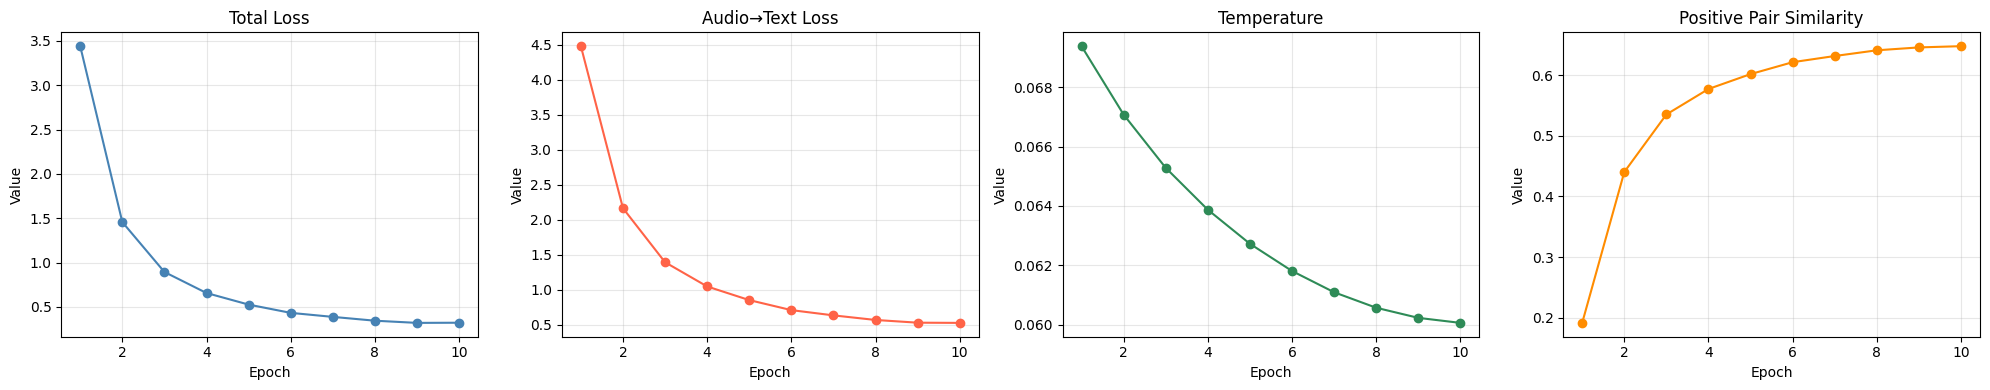

In [12]:
import matplotlib.pyplot as plt
 
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
 
for ax, key, color, title in zip(
    axes,
    ["loss",      "loss_a2t",       "temperature",  "pos_sim"],
    ["steelblue", "tomato",         "seagreen",     "darkorange"],
    ["Total Loss", "Audio→Text Loss", "Temperature", "Positive Pair Similarity"],
):
    ax.plot(epochs, [h[key] for h in history], marker="o", color=color)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Value")
    ax.grid(True, alpha=0.3)
 
plt.tight_layout()
plt.savefig("/kaggle/working/clip_loss_curves.png", dpi=150)
plt.show()


In [13]:
from IPython.display import FileLink
FileLink(r'/kaggle/working/clip_model.pt')

/kaggle/working/clip_model.pt